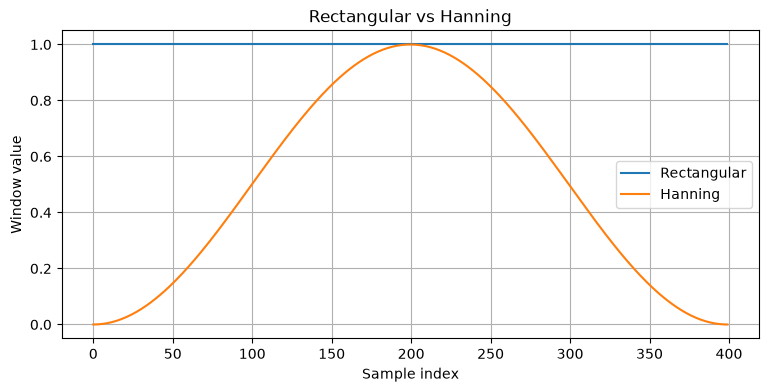

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

#实验1：观察两种窗函数
sr = 16000
win_length = 400

rect_win = np.ones(win_length)

hann_win = np.hanning(win_length)

n = np.arange(win_length)

plt.figure(figsize=(9,4))
plt.plot(n,rect_win,label="Rectangular")
plt.plot(n,hann_win,label="Hanning")

plt.xlabel("Sample index")
plt.ylabel("Window value")
plt.title("Rectangular vs Hanning")
plt.legend()
plt.grid(True)
plt.show()

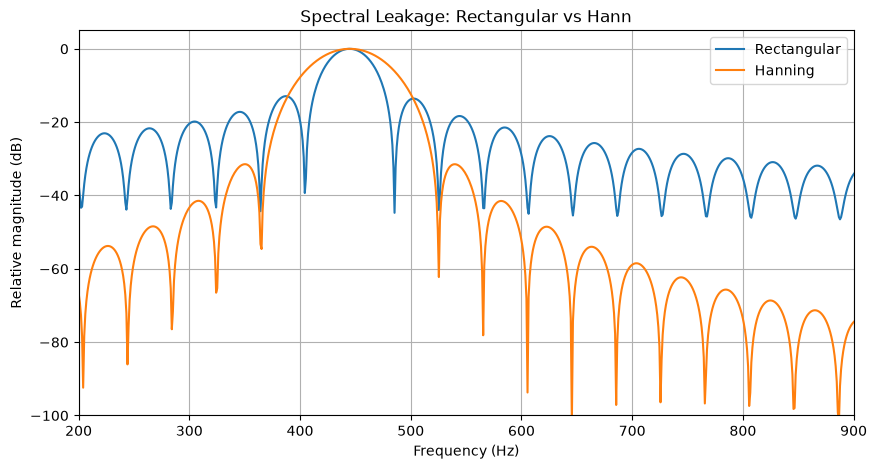

In [2]:
#实验2：使用纯音比较频谱泄露
f = 445
sr = 16000
win_length = 400
n_fft = 16384

t = np.arange(win_length) / sr

x = np.sin(2*np.pi*f*t)

#两种加窗方式
x_rect = x * np.ones(win_length)
x_hann = x * np.hanning(win_length)

#补零后计算rFFT
X_rect = np.fft.rfft(x_rect,n=n_fft)
X_hann = np.fft.rfft(x_hann,n=n_fft)

freqs = np.fft.rfftfreq(n_fft, 1/sr)

mag_rect = np.abs(X_rect)
mag_hann = np.abs(X_hann)

#归一化
mag_rect_norm = mag_rect / (mag_rect.max() + 1e-12)
mag_hann_norm = mag_hann / (mag_hann.max() + 1e-12)

#转为dB
db_rect = 20 * np.log10(mag_rect_norm + 1e-12)
db_hann = 20 * np.log10(mag_hann_norm + 1e-12)

plt.figure(figsize=(10,5))

plt.plot(freqs,db_rect,label="Rectangular")
plt.plot(freqs,db_hann,label="Hanning")

plt.xlim(200,900)
plt.ylim(-100,5)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Relative magnitude (dB)")
plt.title("Spectral Leakage: Rectangular vs Hann")
plt.legend()
plt.grid(True)
plt.show()

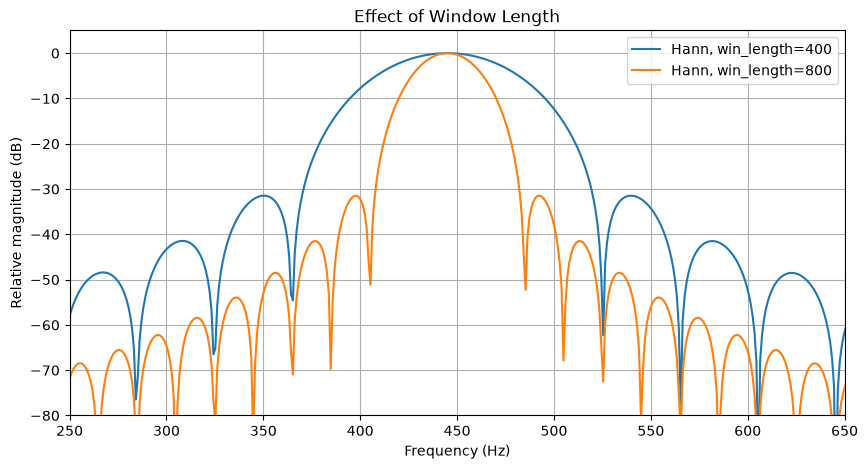

In [3]:
#实验3：改变窗长，观察主瓣宽度
sr = 16000
f = 445
n_fft = 16384

plt.figure(figsize=(10,5))

for win_length in [400,800]:
    t = np.arange(win_length) / sr

    x = np.sin(2*np.pi*f*t)
    win = np.hanning(win_length)

    X = np.fft.rfft(x * win, n=n_fft)

    freqs = np.fft.rfftfreq(n_fft, d=1/sr)

    mag = np.abs(X)
    mag = mag / (mag.max() + 1e-12)

    db = 20 * np.log10(mag + 1e-12)

    plt.plot(
        freqs,
        db,
        label=f"Hann, win_length={win_length}"
    )

plt.xlim(250,650)
plt.ylim(-80,5)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Relative magnitude (dB)")
plt.title("Effect of Window Length")
plt.legend()
plt.grid(True)
plt.show()

In [2]:
#实验4：STFT矩阵形状推导
import numpy as np
import librosa

sr = 16000
N = 16000

win_length = 400
hop_length = 160
n_fft = 512

#1s测试信号
t = np.arange(N) / sr
x = np.sin(2*np.pi*440*t)

#理论频点数
F = n_fft // 2 + 1

# center = False
T_false = 1 + (N - n_fft) // hop_length

#center = True
T_true = 1 + N // hop_length

D_false = librosa.stft(
    x,
    n_fft=n_fft,
    hop_length=hop_length,
    win_length=win_length,
    window="hann",
    center=False
)

D_true = librosa.stft(
    x,
    n_fft=n_fft,
    hop_length=hop_length,
    win_length=win_length,
    window="hann",
    center="True",
    pad_mode="constant"
)

print("center=False")
print("理论 shape:", (F, T_false))
print("实际 shape:", D_false.shape)

print("\ncenter=True")
print("理论 shape:", (F, T_true))
print("实际 shape:", D_true.shape)

assert D_false.shape == (F, T_false)
assert D_true.shape == (F, T_true)

print("\nShape validation passed!")

center=False
理论 shape: (257, 97)
实际 shape: (257, 97)

center=True
理论 shape: (257, 101)
实际 shape: (257, 101)

Shape validation passed!


In [4]:
import sys
from pathlib import Path

import numpy as np
import soundfile as sf
import librosa
import librosa.display
import matplotlib.pyplot as plt

#兼容从项目根目录或notebooks目录启动Jupyter
root = Path.cwd().resolve()

if not (root / "src" / "features.py").exists():
    root = root.parent

assert (root / "src" / "features.py").exists(), (
    "未找到src/features.py，请检查项目运行目录"
)

sys.path.insert(0, str(root))

from src.features import compute_stft,compute_log_magnitude_db

audio_path = root / "data" / "audio" / "test_16k.wav"

audio, sr = sf.read(
    audio_path,
    dtype="float32",
    always_2d=True
)

#转换单声道
waveform = audio.squeeze(axis=1)

n_fft = 512
win_length = 400
hop_length = 160

D = compute_stft(waveform,sr=sr,n_fft=n_fft,win_length=win_length,hop_length=hop_length,center=True)
S_db = compute_log_magnitude_db(D)

print("sr:",sr)
print("音频采样点数:", len(waveform))
print("音频时长:", len(waveform) / sr)
print("STFT shape:", D.shape)
print("dB谱 shape:", S_db.shape)

sr: 16000
音频采样点数: 47616
音频时长: 2.976
STFT shape: (257, 298)
dB谱 shape: (257, 298)


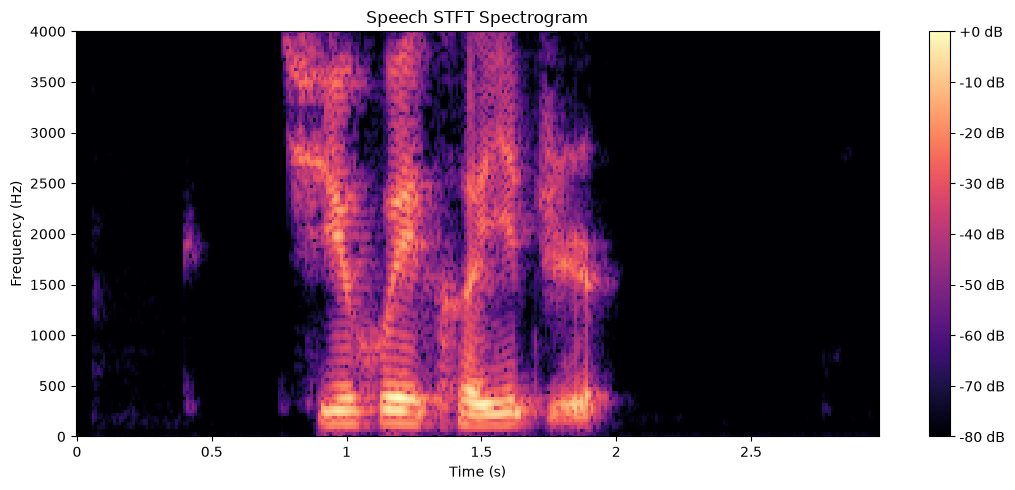

In [5]:
#绘制语谱图
plt.figure(figsize=(11,5))

librosa.display.specshow(
    S_db,
    sr=sr,
    hop_length=hop_length,
    x_axis="time",
    y_axis="linear",
    cmap="magma"
)

plt.ylim(0,4000)
plt.colorbar(format="%+2.0f dB")

plt.title("Speech STFT Spectrogram")
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.tight_layout()
plt.show()